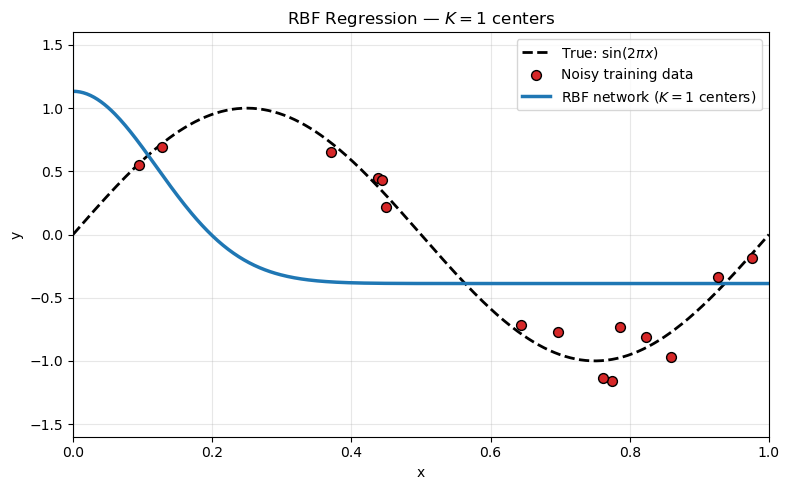

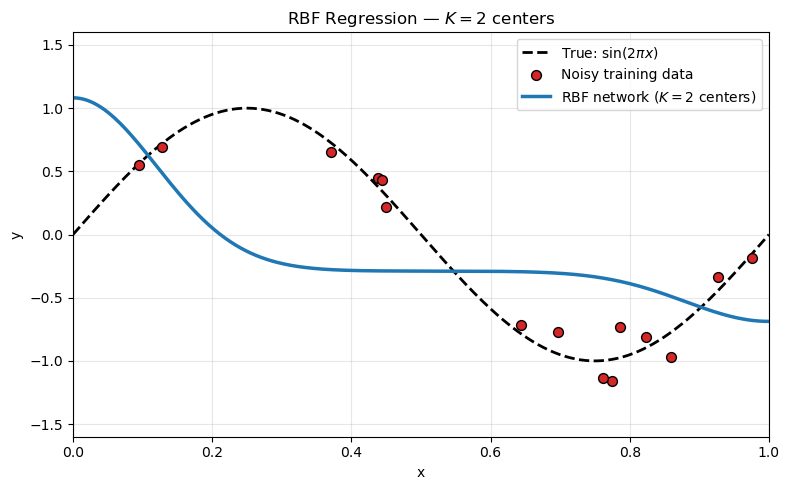

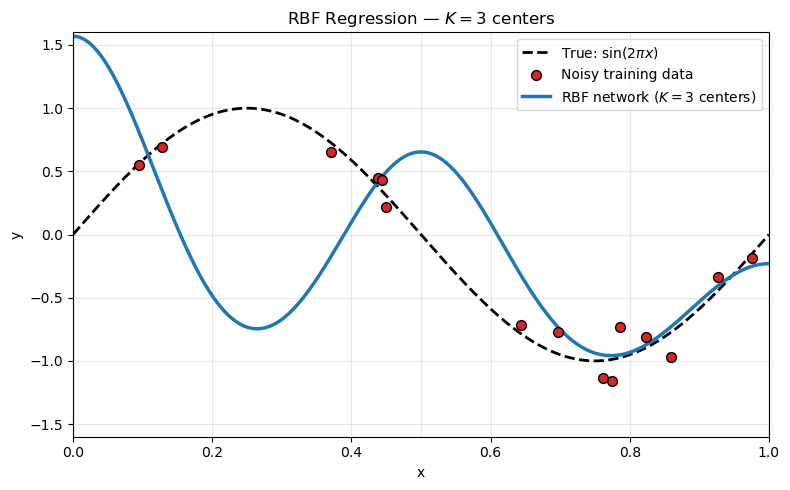

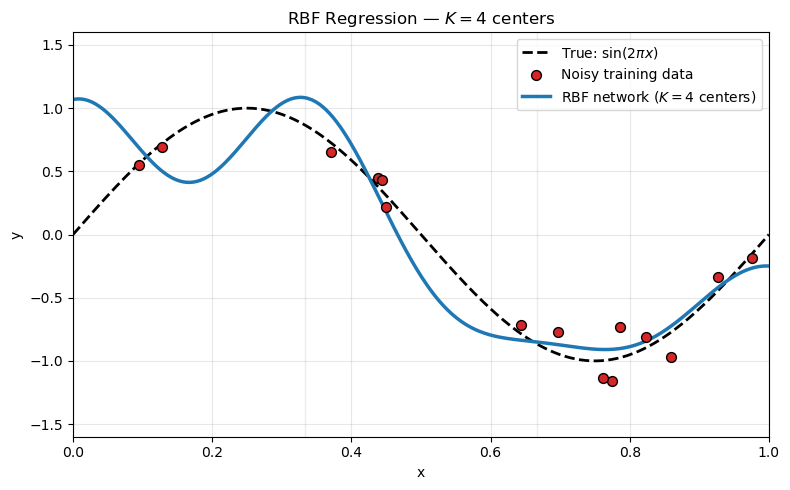

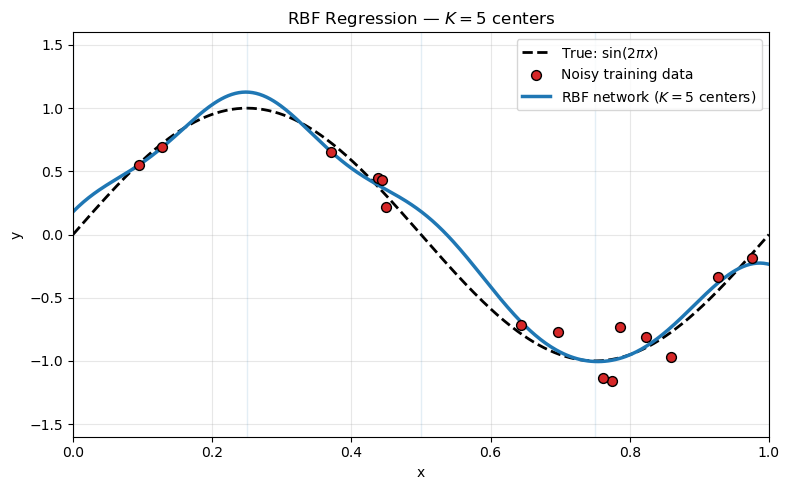

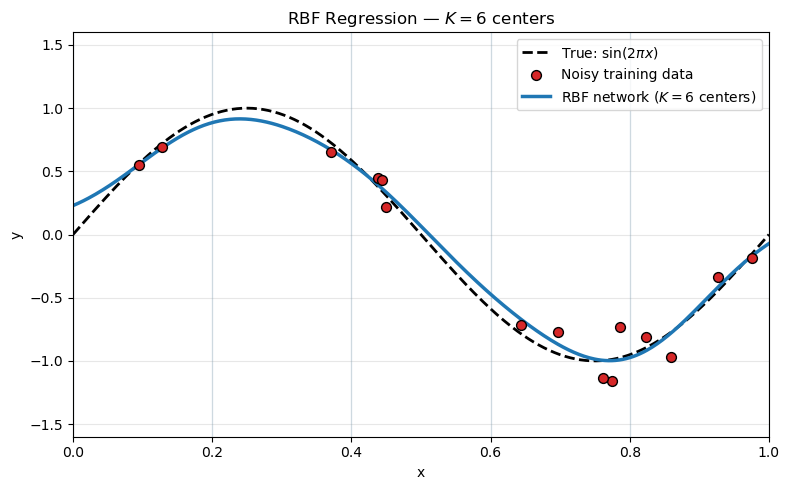

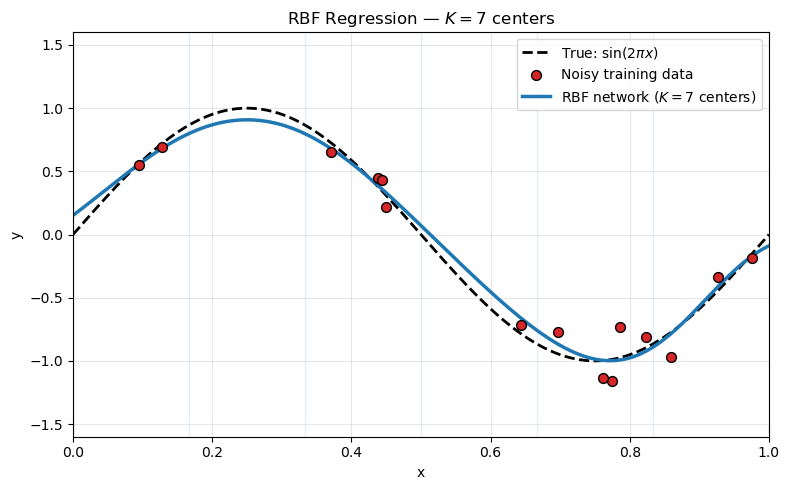

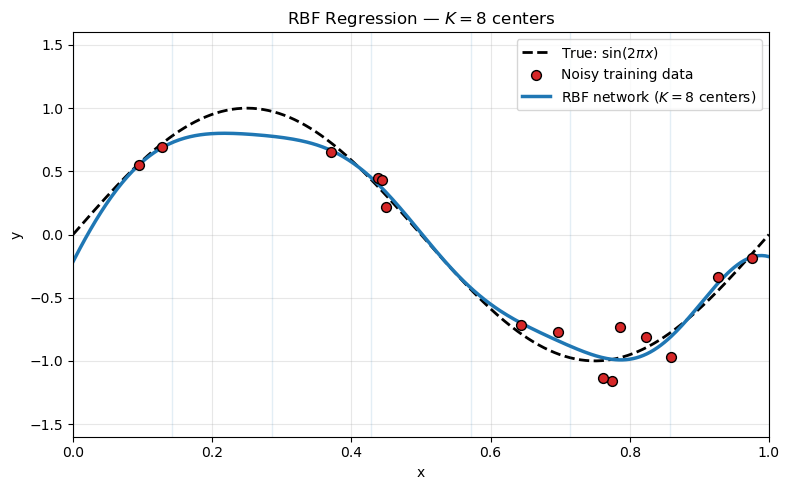

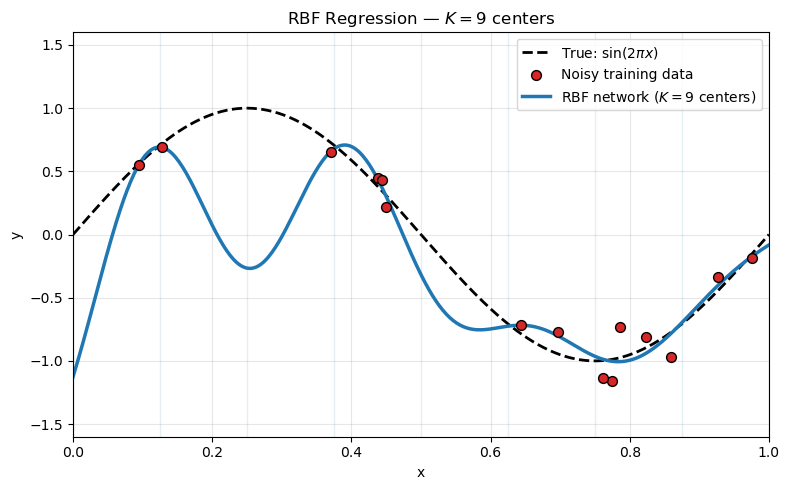

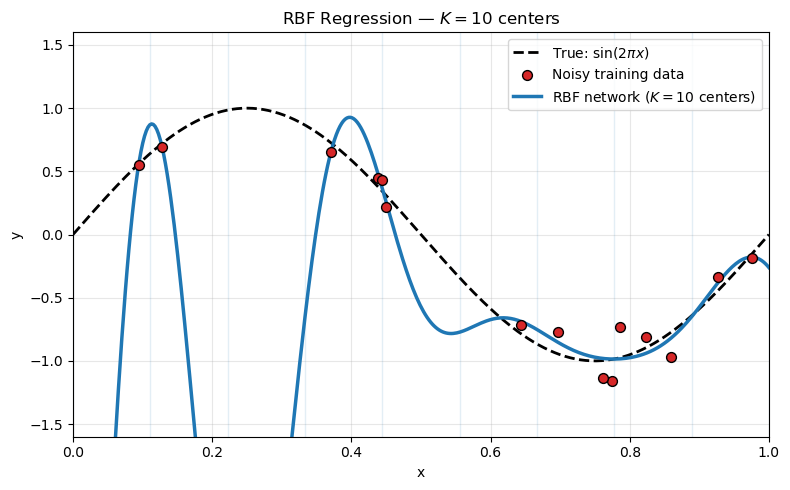

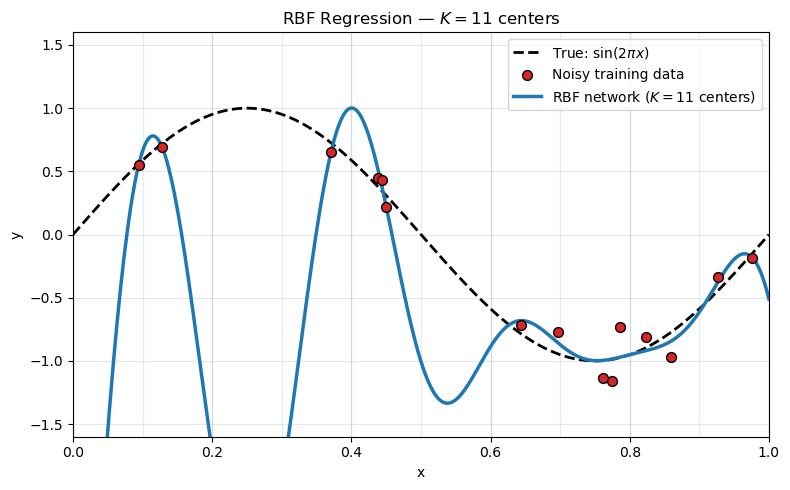

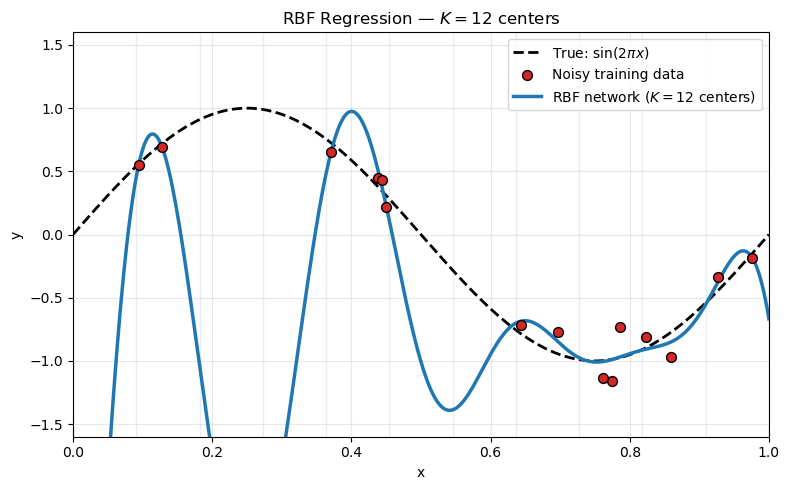

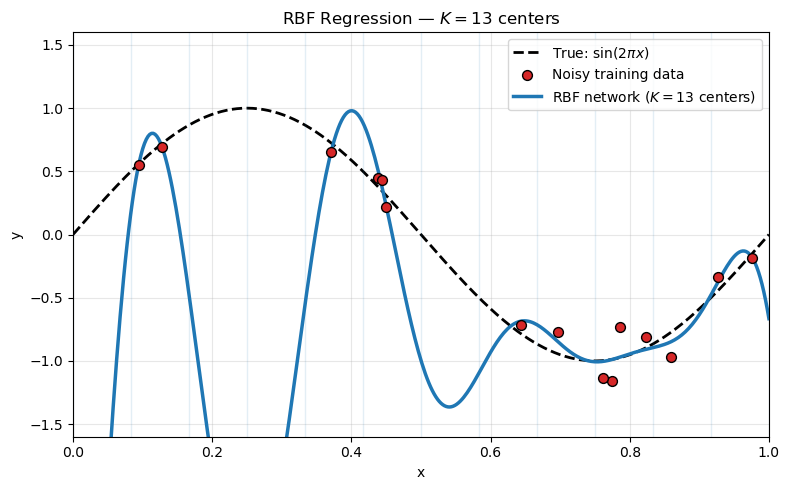

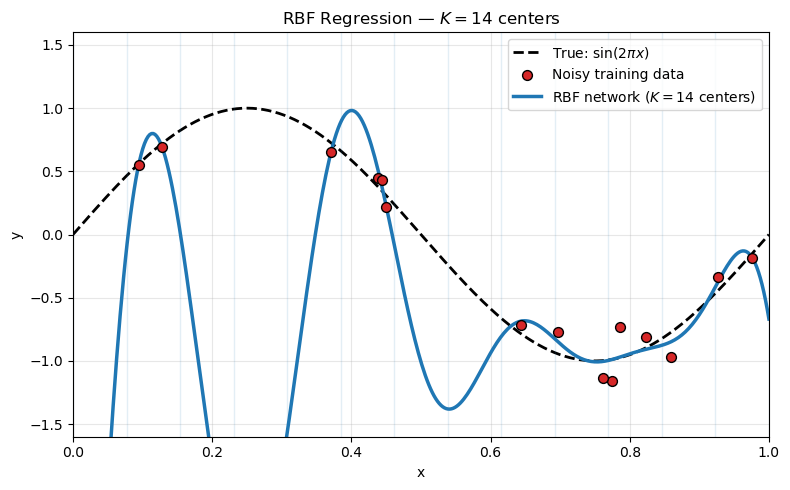

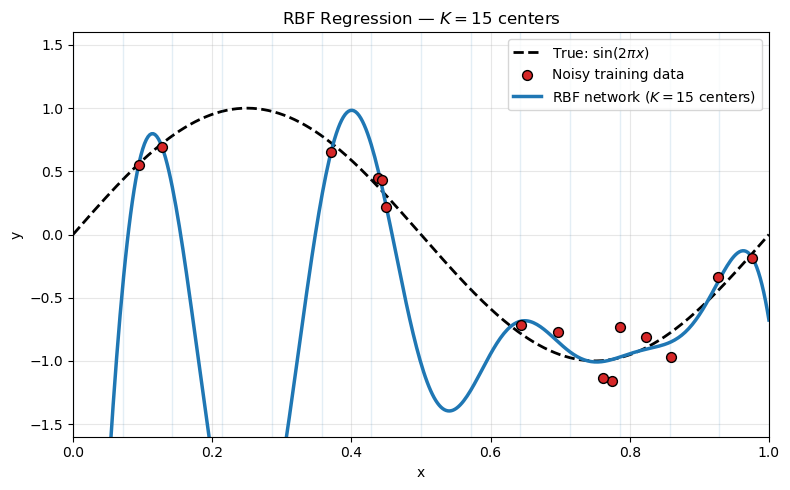

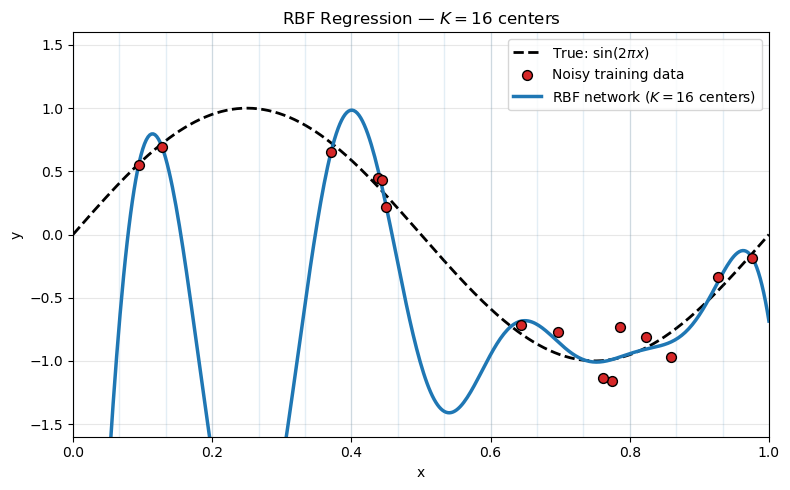

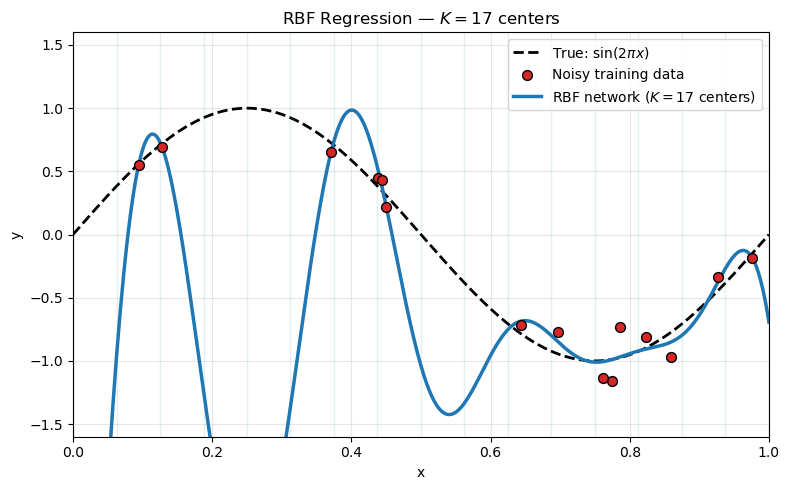

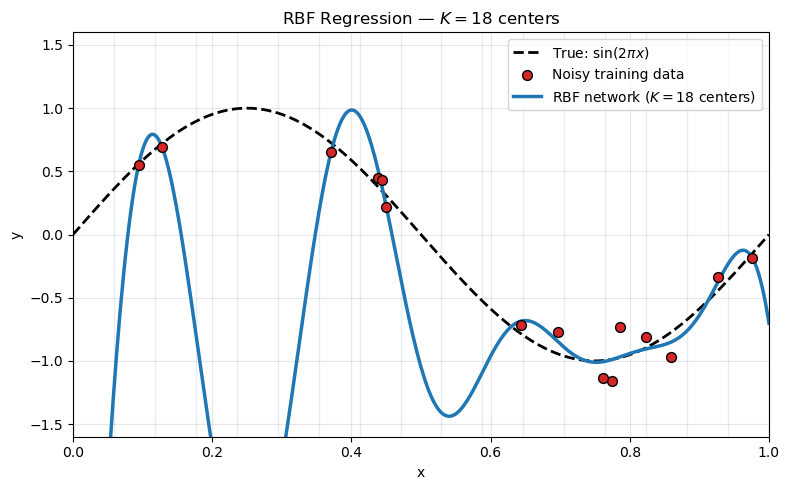

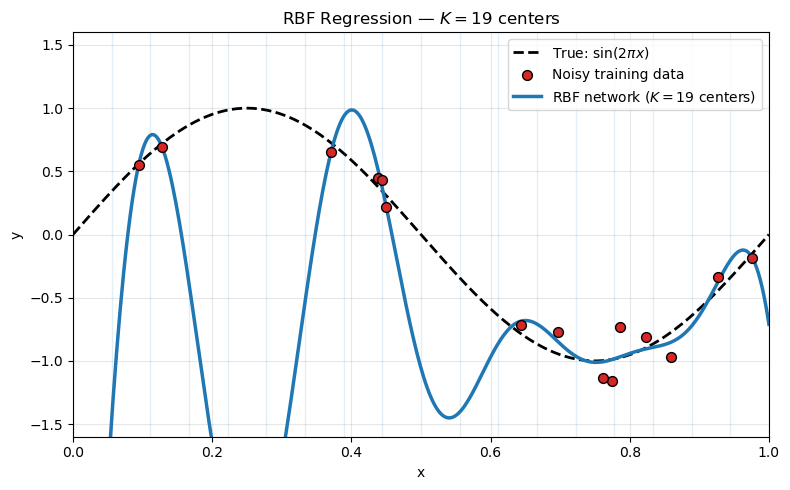

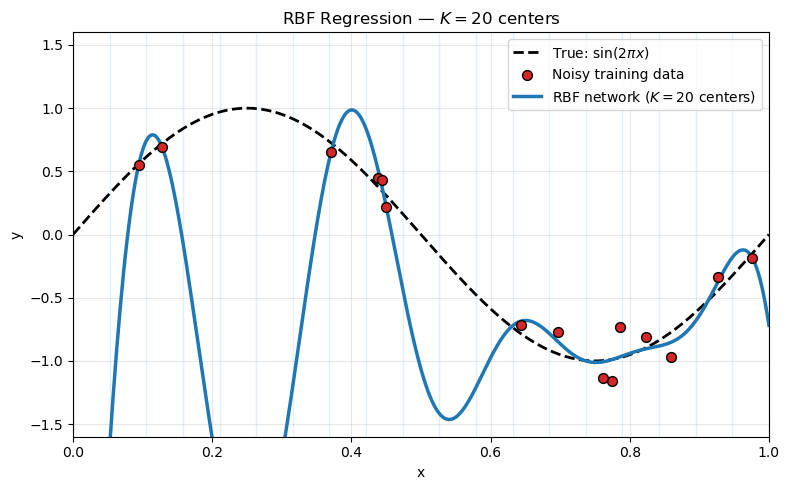

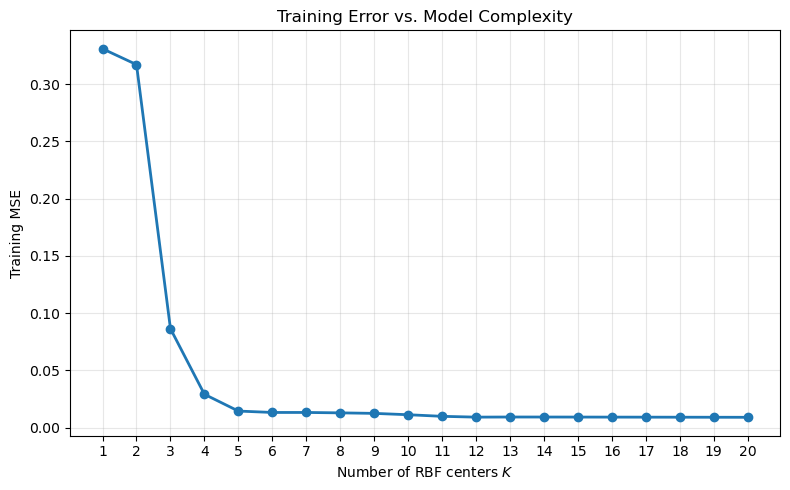

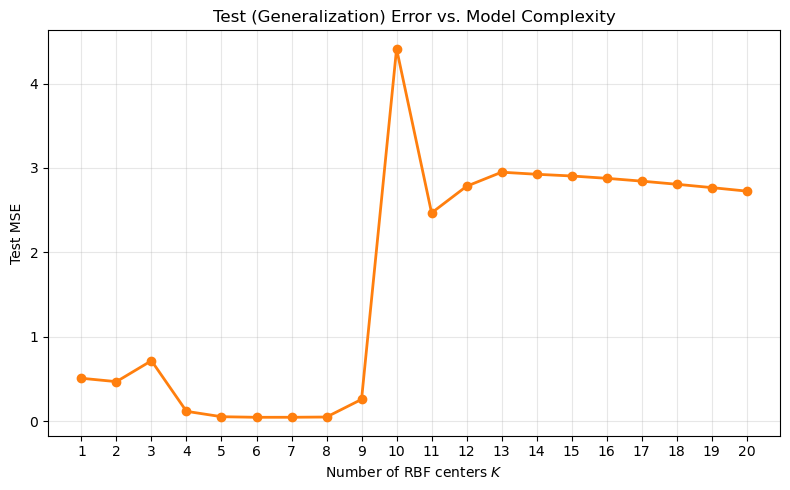

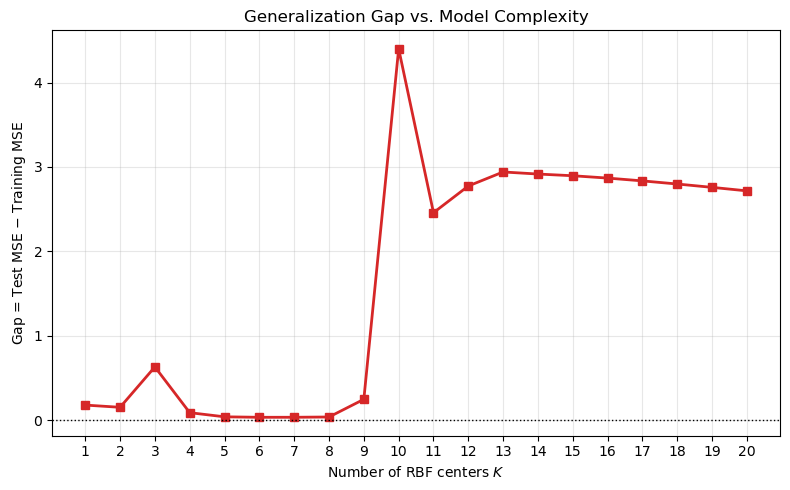

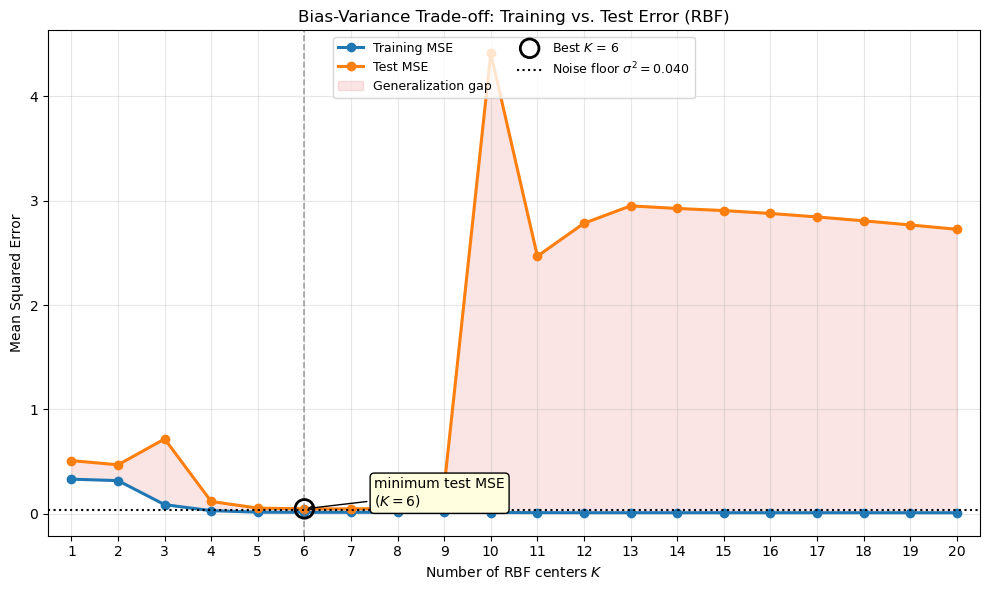

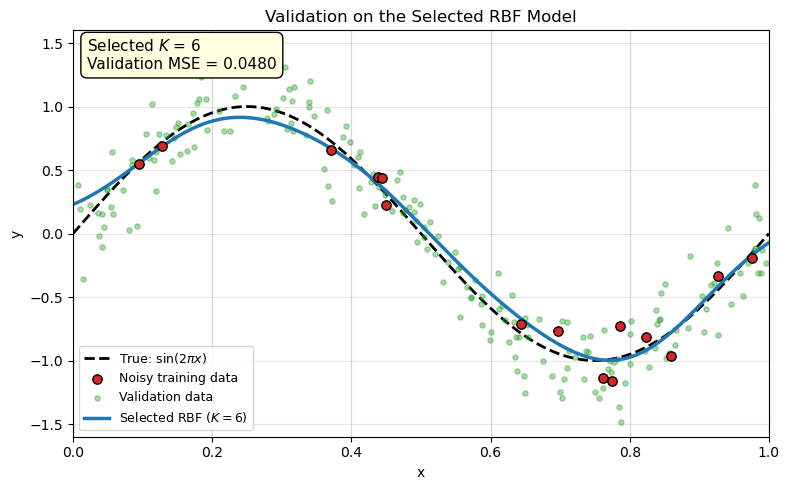


RBF Regression — Model Complexity Report
   K |   Training MSE |     Test MSE
------------------------------------
   1 |        0.33085 |      0.50877
   2 |        0.31702 |      0.46860
   3 |        0.08640 |      0.71672
   4 |        0.02912 |      0.11707
   5 |        0.01448 |      0.05330
   6 |        0.01325 |      0.04632
   7 |        0.01325 |      0.04660
   8 |        0.01290 |      0.04953
   9 |        0.01245 |      0.25867
  10 |        0.01128 |      4.41230
  11 |        0.00988 |      2.46774
  12 |        0.00918 |      2.78345
  13 |        0.00928 |      2.95001
  14 |        0.00927 |      2.92544
  15 |        0.00923 |      2.90519
  16 |        0.00919 |      2.87743
  17 |        0.00915 |      2.84415
  18 |        0.00911 |      2.80710
  19 |        0.00907 |      2.76740
  20 |        0.00903 |      2.72585

  Selected K (lowest test MSE)      : 6
  Training MSE of selected model    : 0.01325
  Test MSE of selected model        : 0.04632
  Validatio

In [1]:
# =============================================================================
# MODEL COMPLEXITY WITH RADIAL BASIS FUNCTIONS (RBFs)
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting with a
# radial basis function network on a noisy sine wave.
#
# Model family:
#     y_hat(x) = sum_{k=1}^{K} w_k * phi( ||x - c_k|| / sigma ) + b
#     phi(r)   = exp( -r^2 )      (Gaussian RBF)
#
# Complexity is controlled by K, the number of basis functions (centers).
# We place K centers uniformly on [0, 1] and fit the linear weights with
# ridge-regularized least squares.
#
# Figures:
#   1. K individual fit plots for K = 1, 2, ..., K_max
#   2. Training MSE vs. K
#   3. Test MSE vs. K  (U-shaped)
#   4. Generalization gap = Test MSE - Training MSE
#   5. Combined training & test error
#   6. Validation on the selected model
#
# Console output:
#   Table of (K, training MSE, test MSE)
#   Best K, with train/test/validation MSE.
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error


# =============================================================================
# 1. REPRODUCIBILITY AND CONFIG
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TRAIN = 15            # small training set -> visible under/overfitting
N_TEST = 200
N_VALID = 200

NOISE_SIGMA = 0.20
K_VALUES = list(range(1, 21))    # number of RBF centers (complexity axis)

# Width of the Gaussian bumps (a common heuristic: spacing between centers)
RBF_SIGMA = 0.12


# =============================================================================
# 2. TRUE FUNCTION AND DATA GENERATION
# =============================================================================
def true_function(x):
    """Ground-truth: y = sin(2 * pi * x)."""
    return np.sin(2.0 * np.pi * x)


def sample_points(n, rng):
    """Return n uniform samples on [0, 1] and their noisy targets."""
    x = rng.uniform(0.0, 1.0, size=n).reshape(-1, 1)
    y = true_function(x.ravel()) + rng.normal(0.0, NOISE_SIGMA, size=n)
    return x, y


X_train, y_train = sample_points(N_TRAIN, rng)
X_test, y_test = sample_points(N_TEST, rng)
X_valid, y_valid = sample_points(N_VALID, rng)

X_grid = np.linspace(0.0, 1.0, 400).reshape(-1, 1)
y_grid_true = true_function(X_grid.ravel())


# =============================================================================
# 3. RBF FEATURE MAP
# =============================================================================
def make_centers(K):
    """Uniformly spaced centers in [0, 1]."""
    return np.linspace(0.0, 1.0, K).reshape(-1, 1)


def rbf_design_matrix(X, centers, sigma=RBF_SIGMA):
    """Return the design matrix Phi with entries
        Phi[i, k] = exp( -||x_i - c_k||^2 / (2 * sigma^2) ).
    Shape: (len(X), K).
    """
    # Pairwise squared distances: (N, K)
    d2 = (X - centers.T) ** 2
    return np.exp(-d2 / (2.0 * sigma ** 2))


# =============================================================================
# 4. FIT AN RBF MODEL OF GIVEN COMPLEXITY K
# =============================================================================
def fit_rbf(K, alpha=1e-6):
    """Fit an RBF model with K centers and return it plus train/test MSEs.

    We use Ridge (L2 penalty) with a very small alpha as a numerically safe
    version of ordinary least squares. Set alpha=0 for pure OLS.
    """
    centers = make_centers(K)
    Phi_train = rbf_design_matrix(X_train, centers)
    Phi_test = rbf_design_matrix(X_test, centers)

    model = Ridge(alpha=alpha, fit_intercept=True)
    model.fit(Phi_train, y_train)

    y_train_pred = model.predict(Phi_train)
    y_test_pred = model.predict(Phi_test)

    mse_train = mean_squared_error(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)

    # Bundle everything needed for prediction later
    bundle = {
        "centers": centers,
        "model": model,
        "sigma": RBF_SIGMA,
    }
    return bundle, mse_train, mse_test


def rbf_predict(bundle, X):
    """Predict with a fitted RBF bundle on new inputs X."""
    Phi = rbf_design_matrix(X, bundle["centers"], bundle["sigma"])
    return bundle["model"].predict(Phi)


# =============================================================================
# 5. INDIVIDUAL FIT PLOT FOR EACH K
# =============================================================================
def plot_fit(K, bundle):
    y_grid_pred = rbf_predict(bundle, X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2, label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=50, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=rf"RBF network ($K = {K}$ centers)")

    # Show the centers as vertical ticks
    for c in bundle["centers"].ravel():
        ax.axvline(c, color="tab:blue", alpha=0.12, lw=1)

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(rf"RBF Regression — $K = {K}$ centers")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.savefig(f"rbf_fit_K_{K:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 6. FIT ALL COMPLEXITIES AND COLLECT ERRORS
# =============================================================================
def fit_all(K_values):
    results = {}
    for K in K_values:
        bundle, mse_train, mse_test = fit_rbf(K)
        results[K] = {
            "bundle": bundle,
            "mse_train": mse_train,
            "mse_test": mse_test,
        }
        plot_fit(K, bundle)
    return results


results = fit_all(K_VALUES)

Ks = np.array(K_VALUES)
mse_train = np.array([results[K]["mse_train"] for K in Ks])
mse_test = np.array([results[K]["mse_test"] for K in Ks])
gap = mse_test - mse_train


# =============================================================================
# 7. TRAINING ERROR vs. K
# =============================================================================
def plot_train_error(Ks, mse_train):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ks, mse_train, "-o", lw=2, color="tab:blue")
    ax.set_xlabel("Number of RBF centers $K$")
    ax.set_ylabel("Training MSE")
    ax.set_title("Training Error vs. Model Complexity")
    ax.set_xticks(Ks)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("rbf_training_error_vs_K.png", dpi=120)
    plt.show()


# =============================================================================
# 8. TEST ERROR vs. K
# =============================================================================
def plot_test_error(Ks, mse_test):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ks, mse_test, "-o", lw=2, color="tab:orange")
    ax.set_xlabel("Number of RBF centers $K$")
    ax.set_ylabel("Test MSE")
    ax.set_title("Test (Generalization) Error vs. Model Complexity")
    ax.set_xticks(Ks)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("rbf_test_error_vs_K.png", dpi=120)
    plt.show()


# =============================================================================
# 9. GENERALIZATION GAP
# =============================================================================
def plot_gap(Ks, gap):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(Ks, gap, "-s", lw=2, color="tab:red")
    ax.axhline(0.0, color="black", lw=1, linestyle=":")
    ax.set_xlabel("Number of RBF centers $K$")
    ax.set_ylabel(r"Gap = Test MSE $-$ Training MSE")
    ax.set_title("Generalization Gap vs. Model Complexity")
    ax.set_xticks(Ks)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("rbf_generalization_gap_vs_K.png", dpi=120)
    plt.show()


# =============================================================================
# 10. COMBINED TRAINING AND TEST ERROR
# =============================================================================
def plot_train_test_combined(Ks, mse_train, mse_test,
                             best_K=None, noise_sigma=None):
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(Ks, mse_train, "-o", lw=2.2, color="tab:blue",
            markersize=6, label="Training MSE")
    ax.plot(Ks, mse_test, "-o", lw=2.2, color="tab:orange",
            markersize=6, label="Test MSE")

    ax.fill_between(Ks, mse_train, mse_test,
                    where=(mse_test >= mse_train),
                    color="tab:red", alpha=0.12,
                    label="Generalization gap")
    ax.fill_between(Ks, mse_test, mse_train,
                    where=(mse_train > mse_test),
                    color="tab:green", alpha=0.12)

    if best_K is not None:
        best_idx = int(np.where(Ks == best_K)[0][0])
        ax.axvline(best_K, color="gray", lw=1.2, linestyle="--", alpha=0.7)
        ax.scatter([best_K], [mse_test[best_idx]],
                   s=180, facecolor="none", edgecolor="black",
                   linewidth=2, zorder=5, label=f"Best $K$ = {best_K}")
        ax.annotate(
            f"minimum test MSE\n($K = {best_K}$)",
            xy=(best_K, mse_test[best_idx]),
            xytext=(best_K + 1.5, mse_test[best_idx] + 0.03),
            fontsize=10,
            arrowprops=dict(arrowstyle="->", color="black", lw=1),
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor="lightyellow", edgecolor="black"),
        )

    if noise_sigma is not None:
        ax.axhline(noise_sigma ** 2, color="k", linestyle=":", lw=1.5,
                   label=rf"Noise floor $\sigma^2 = {noise_sigma**2:.3f}$")

    ax.set_xlim(0.5, Ks.max() + 0.5)
    ax.set_xticks(Ks)
    ax.set_xlabel("Number of RBF centers $K$")
    ax.set_ylabel("Mean Squared Error")
    ax.set_title("Bias-Variance Trade-off: Training vs. Test Error (RBF)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper center", ncol=2, fontsize=9)

    plt.tight_layout()
    plt.savefig("rbf_train_test_error_combined.png", dpi=120)
    plt.show()


# =============================================================================
# 11. VALIDATION ON THE SELECTED MODEL
# =============================================================================
def plot_validation(selected_K, bundle, mse_valid):
    y_grid_pred = rbf_predict(bundle, X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2,
            label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=45, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.scatter(X_valid, y_valid, s=14, c="tab:green", alpha=0.4,
               zorder=2, label="Validation data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=rf"Selected RBF ($K = {selected_K}$)")

    for c in bundle["centers"].ravel():
        ax.axvline(c, color="tab:blue", alpha=0.12, lw=1)

    ax.annotate(
        f"Selected $K$ = {selected_K}\n"
        f"Validation MSE = {mse_valid:.4f}",
        xy=(0.02, 0.98), xycoords="axes fraction",
        ha="left", va="top", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="lightyellow", edgecolor="black"),
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Validation on the Selected RBF Model")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    plt.savefig("rbf_validation_selected_model.png", dpi=120)
    plt.show()


# =============================================================================
# 12. REPORTING
# =============================================================================
def print_table(Ks, mse_train, mse_test):
    header = f"{'K':>4} | {'Training MSE':>14} | {'Test MSE':>12}"
    print(header)
    print("-" * len(header))
    for K, mtr, mte in zip(Ks, mse_train, mse_test):
        print(f"{K:>4d} | {mtr:>14.5f} | {mte:>12.5f}")


def select_best_K(Ks, mse_test):
    idx = int(np.argmin(mse_test))
    return int(Ks[idx])


# =============================================================================
# 13. MAIN
# =============================================================================
def main():
    # ---- Summary figures ----
    plot_train_error(Ks, mse_train)
    plot_test_error(Ks, mse_test)
    plot_gap(Ks, gap)

    # ---- Combined train/test error ----
    best_K = select_best_K(Ks, mse_test)
    plot_train_test_combined(
        Ks, mse_train, mse_test,
        best_K=best_K,
        noise_sigma=NOISE_SIGMA,
    )

    # ---- Validation on selected model ----
    best_bundle = results[best_K]["bundle"]
    y_valid_pred = rbf_predict(best_bundle, X_valid)
    mse_valid = mean_squared_error(y_valid, y_valid_pred)
    plot_validation(best_K, best_bundle, mse_valid)

    # ---- Console report ----
    print()
    print("=" * 50)
    print("RBF Regression — Model Complexity Report")
    print("=" * 50)
    print_table(Ks, mse_train, mse_test)

    print()
    print(f"  Selected K (lowest test MSE)      : {best_K}")
    print(f"  Training MSE of selected model    : {mse_train[best_K - 1]:.5f}")
    print(f"  Test MSE of selected model        : {mse_test[best_K - 1]:.5f}")
    print(f"  Validation MSE of selected model  : {mse_valid:.5f}")

    print()
    print("Educational interpretation:")
    print("  * Small K   -> underfitting (too few bumps to capture the sine).")
    print("  * Mid K     -> good fit (bumps trace the curve).")
    print("  * Large K   -> overfitting (bumps chase individual noise points).")
    print("  * Gap = Test - Train grows with K.")


if __name__ == "__main__":
    main()